<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/main/DL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error



In [4]:
df = pd.read_csv('/content/train.csv')

In [5]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (188533, 13)

First 5 rows:


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Missing values:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0


In [6]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [7]:
# Statistical summary of numerical columns

display(df.describe())

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Price Statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


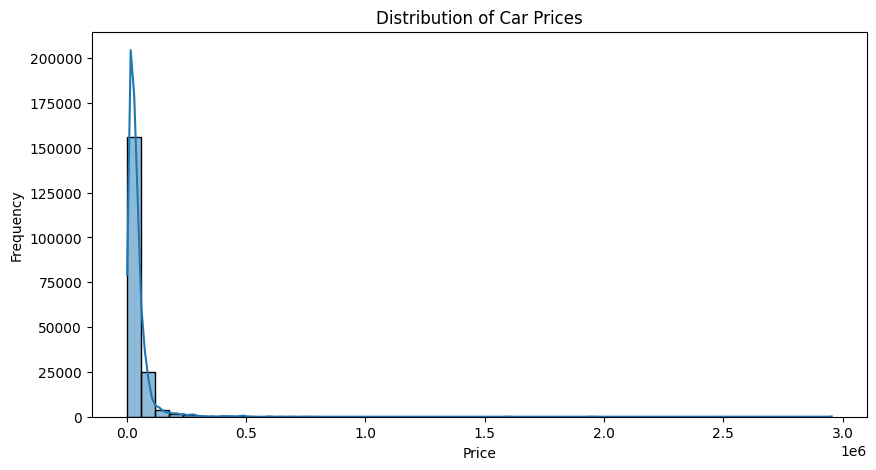

In [8]:
# Analyze target variable

print("Price Statistics:")
print(df['price'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [9]:
# Number of unique values in each categorical column

for col in categorical_cols:
    print(col, ":", df[col].nunique())

brand : 57
model : 1897
fuel_type : 7
engine : 1117
transmission : 52
ext_col : 319
int_col : 156
accident : 2
clean_title : 1


In [10]:
# Create a copy of the dataset
df = df.copy()

# Remove unnecessary ID column
df = df.drop(columns=['id'])

print("ID column removed successfully!")
print("New dataset shape:", df.shape)

ID column removed successfully!
New dataset shape: (188533, 12)


In [11]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove unnecessary whitespace
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Convert empty strings into missing values
df[categorical_cols] = df[categorical_cols].replace(r'^\s*$', np.nan, regex=True)

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [12]:
# Fill missing categorical values
for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [13]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Missing values after cleaning:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

Dataset shape:
(188533, 12)

First 5 rows:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [14]:
# Separate features and target

X = df.drop(columns=['price'])
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (188533, 11)
Target shape: (188533,)

Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [15]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (131973, 11)
Validation set: (28280, 11)
Testing set: (28280, 11)


In [16]:
# Calculate dataset percentages

total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [17]:
#Apply One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    max_categories=50,
    sparse_output=False
)

# Fit on training data and transform all datasets
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = encoder.transform(
    X_val[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Convert to float32
X_train_cat = X_train_cat.astype(np.float32)
X_val_cat = X_val_cat.astype(np.float32)
X_test_cat = X_test_cat.astype(np.float32)

print("\nEncoding completed successfully!")

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Testing categorical shape:", X_test_cat.shape)

print("\nTotal encoded features:", X_train_cat.shape[1])

Categorical features:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Encoding completed successfully!
Training categorical shape: (131973, 313)
Validation categorical shape: (28280, 313)
Testing categorical shape: (28280, 313)

Total encoded features: 313


In [18]:
#Import and create the scaler

from sklearn.preprocessing import StandardScaler

# Identify numerical features
numerical_features = ['model_year', 'milage']

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform validation and testing data
X_val_num = scaler.transform(
    X_val[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Numerical scaling completed!")

print("Training numerical shape:", X_train_num.shape)
print("Validation numerical shape:", X_val_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Numerical scaling completed!
Training numerical shape: (131973, 2)
Validation numerical shape: (28280, 2)
Testing numerical shape: (28280, 2)


In [19]:
print("Training numerical means:")
print(X_train_num.mean(axis=0))

print("\nTraining numerical standard deviations:")
print(X_train_num.std(axis=0))

Training numerical means:
[7.73228657e-15 7.90371315e-17]

Training numerical standard deviations:
[1. 1.]


In [20]:
# Combine numerical and categorical features

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_val_final = np.concatenate(
    [X_val_num, X_val_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final feature shapes:")

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Final feature shapes:
Training: (131973, 315)
Validation: (28280, 315)
Testing: (28280, 315)


In [21]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create target scaler
target_scaler = StandardScaler()

# Fit on training prices only
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Transform validation and testing prices
y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = target_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target scaling completed!")
print("Training target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Target scaling completed!
Training target mean: 9.475841383751042e-18
Training target std: 1.0


In [22]:
# Convert features to float32
X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [23]:
print("Training features:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation features:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)

Training features: torch.Size([131973, 315])
Training target: torch.Size([131973, 1])
Validation features: torch.Size([28280, 315])
Validation target: torch.Size([28280, 1])
Testing features: torch.Size([28280, 315])
Testing target: torch.Size([28280, 1])


In [24]:
# Define Linear Regression model

class LinearRegressionModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.linear = nn.Linear(input_size, 1)

    def forward(self, x):
        return self.linear(x)


# Create the model
linear_model = LinearRegressionModel(input_size=315)

print(linear_model)

LinearRegressionModel(
  (linear): Linear(in_features=315, out_features=1, bias=True)
)


In [25]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

# Number of epochs
epochs = 30

print("Training setup completed!")

Training setup completed!


In [26]:
# Store training and validation losses
linear_train_losses = []
linear_val_losses = []

for epoch in range(epochs):

    # Training mode
    linear_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        # Forward pass
        predictions = linear_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    linear_model.eval()

    with torch.no_grad():

        val_predictions = linear_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    linear_train_losses.append(train_loss)
    linear_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Linear Regression training completed!")

Epoch [1/30], Train Loss: 0.8932, Val Loss: 0.7074
Epoch [2/30], Train Loss: 0.8880, Val Loss: 0.7089
Epoch [3/30], Train Loss: 0.8886, Val Loss: 0.7084
Epoch [4/30], Train Loss: 0.8887, Val Loss: 0.7150
Epoch [5/30], Train Loss: 0.8885, Val Loss: 0.7072
Epoch [6/30], Train Loss: 0.8881, Val Loss: 0.7027
Epoch [7/30], Train Loss: 0.8883, Val Loss: 0.7062
Epoch [8/30], Train Loss: 0.8881, Val Loss: 0.7046
Epoch [9/30], Train Loss: 0.8884, Val Loss: 0.7061
Epoch [10/30], Train Loss: 0.8883, Val Loss: 0.7088
Epoch [11/30], Train Loss: 0.8885, Val Loss: 0.7115
Epoch [12/30], Train Loss: 0.8882, Val Loss: 0.7114
Epoch [13/30], Train Loss: 0.8888, Val Loss: 0.7065
Epoch [14/30], Train Loss: 0.8880, Val Loss: 0.7125
Epoch [15/30], Train Loss: 0.8891, Val Loss: 0.7083
Epoch [16/30], Train Loss: 0.8877, Val Loss: 0.7095
Epoch [17/30], Train Loss: 0.8882, Val Loss: 0.7053
Epoch [18/30], Train Loss: 0.8879, Val Loss: 0.7078
Epoch [19/30], Train Loss: 0.8890, Val Loss: 0.7099
Epoch [20/30], Train 

In [27]:
# Convert predictions back to original price scale

linear_model.eval()

with torch.no_grad():

    train_pred_scaled = linear_model(X_train_tensor).numpy()
    val_pred_scaled = linear_model(X_val_tensor).numpy()

    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

linear_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Linear Regression Results")
print("--------------------------")
print("Training MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)

Linear Regression Results
--------------------------
Training MSE: 5850798080.0
Validation MSE: 4675743232.0


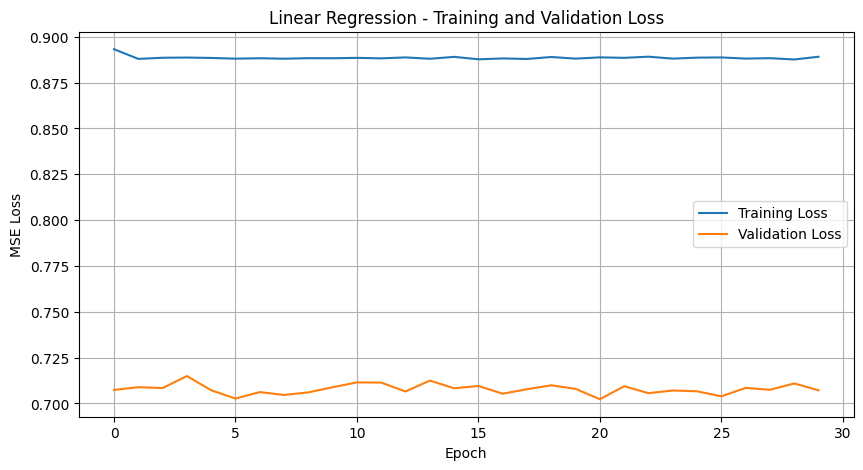

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    linear_train_losses,
    label="Training Loss"
)

plt.plot(
    linear_val_losses,
    label="Validation Loss"
)

plt.title("Linear Regression - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [29]:
# Define Deep Neural Network

class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
dnn_model = DeepNeuralNetwork(input_size=315)

print(dnn_model)

DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [30]:
# Create DataLoader for DNN

dnn_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
dnn_optimizer = optim.Adam(
    dnn_model.parameters(),
    lr=0.001
)

# Number of epochs
epochs = 30

print("DNN training setup completed!")

DNN training setup completed!


In [31]:
# Store training and validation losses

dnn_train_losses = []
dnn_val_losses = []

for epoch in range(epochs):

    dnn_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = dnn_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        dnn_optimizer.zero_grad()

        loss.backward()

        dnn_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    dnn_model.eval()

    with torch.no_grad():

        val_predictions = dnn_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    dnn_train_losses.append(train_loss)
    dnn_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("DNN training completed!")

Epoch [1/30], Train Loss: 0.8811, Val Loss: 0.6835
Epoch [2/30], Train Loss: 0.8660, Val Loss: 0.6865
Epoch [3/30], Train Loss: 0.8617, Val Loss: 0.6869
Epoch [4/30], Train Loss: 0.8586, Val Loss: 0.6823
Epoch [5/30], Train Loss: 0.8543, Val Loss: 0.6876
Epoch [6/30], Train Loss: 0.8489, Val Loss: 0.6909
Epoch [7/30], Train Loss: 0.8442, Val Loss: 0.6912
Epoch [8/30], Train Loss: 0.8368, Val Loss: 0.6963
Epoch [9/30], Train Loss: 0.8320, Val Loss: 0.6919
Epoch [10/30], Train Loss: 0.8184, Val Loss: 0.6915
Epoch [11/30], Train Loss: 0.7991, Val Loss: 0.6941
Epoch [12/30], Train Loss: 0.7822, Val Loss: 0.6942
Epoch [13/30], Train Loss: 0.7567, Val Loss: 0.7050
Epoch [14/30], Train Loss: 0.7378, Val Loss: 0.7075
Epoch [15/30], Train Loss: 0.7134, Val Loss: 0.7221
Epoch [16/30], Train Loss: 0.7003, Val Loss: 0.7094
Epoch [17/30], Train Loss: 0.6797, Val Loss: 0.7012
Epoch [18/30], Train Loss: 0.6654, Val Loss: 0.7401
Epoch [19/30], Train Loss: 0.6616, Val Loss: 0.7341
Epoch [20/30], Train 

In [32]:
# Evaluate DNN

dnn_model.eval()

with torch.no_grad():

    train_pred_scaled = dnn_model(X_train_tensor).numpy()

    val_pred_scaled = dnn_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
dnn_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

dnn_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Deep Neural Network Results")
print("---------------------------")

print("Training MSE:", dnn_train_mse)

print("Validation MSE:", dnn_val_mse)

Deep Neural Network Results
---------------------------
Training MSE: 3735168000.0
Validation MSE: 4939790848.0


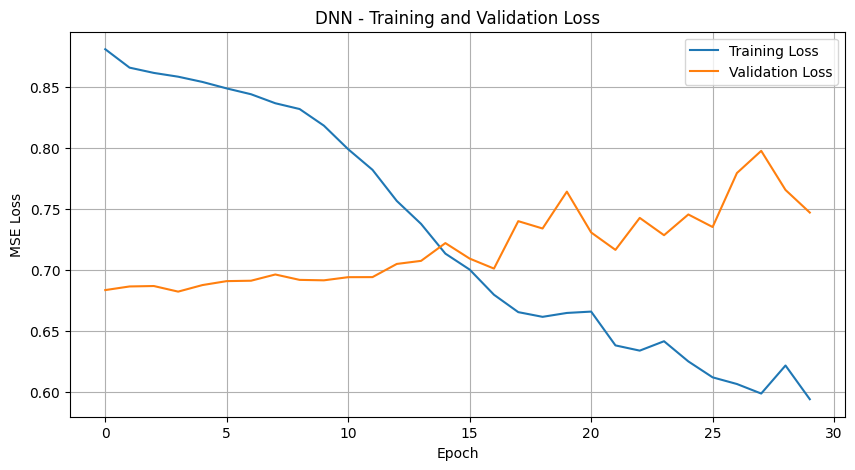

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    dnn_train_losses,
    label="Training Loss"
)

plt.plot(
    dnn_val_losses,
    label="Validation Loss"
)

plt.title("DNN - Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [34]:
# Compare baseline models

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        dnn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        dnn_val_mse
    ]

})

display(comparison)

,Model,Training MSE,Validation MSE
0,Linear Regression,5.850798e+09,4.675743e+09
1,Deep Neural Network,3.735168e+09,4.939791e+09


In [35]:
# Create a fresh DNN model
exp1_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with a lower learning rate
exp1_optimizer = optim.Adam(
    exp1_model.parameters(),
    lr=0.0001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp1_train_losses = []
exp1_val_losses = []

print("Experiment 1 setup completed!")

Experiment 1 setup completed!


In [36]:
# Train Experiment 1

for epoch in range(30):

    exp1_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp1_model(X_batch)

        loss = criterion(predictions, y_batch)

        exp1_optimizer.zero_grad()

        loss.backward()

        exp1_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp1_model.eval()

    with torch.no_grad():

        val_predictions = exp1_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 1 completed!")

Epoch [1/30], Train Loss: 0.9248, Val Loss: 0.6981
Epoch [2/30], Train Loss: 0.8756, Val Loss: 0.6861
Epoch [3/30], Train Loss: 0.8679, Val Loss: 0.6841
Epoch [4/30], Train Loss: 0.8648, Val Loss: 0.6829
Epoch [5/30], Train Loss: 0.8629, Val Loss: 0.6823
Epoch [6/30], Train Loss: 0.8614, Val Loss: 0.6823
Epoch [7/30], Train Loss: 0.8603, Val Loss: 0.6822
Epoch [8/30], Train Loss: 0.8587, Val Loss: 0.6854
Epoch [9/30], Train Loss: 0.8578, Val Loss: 0.6829
Epoch [10/30], Train Loss: 0.8569, Val Loss: 0.6826
Epoch [11/30], Train Loss: 0.8555, Val Loss: 0.6851
Epoch [12/30], Train Loss: 0.8544, Val Loss: 0.6839
Epoch [13/30], Train Loss: 0.8534, Val Loss: 0.6839
Epoch [14/30], Train Loss: 0.8524, Val Loss: 0.6831
Epoch [15/30], Train Loss: 0.8513, Val Loss: 0.6828
Epoch [16/30], Train Loss: 0.8498, Val Loss: 0.6843
Epoch [17/30], Train Loss: 0.8488, Val Loss: 0.6883
Epoch [18/30], Train Loss: 0.8479, Val Loss: 0.6851
Epoch [19/30], Train Loss: 0.8467, Val Loss: 0.6857
Epoch [20/30], Train 

In [37]:
# Evaluate Experiment 1

exp1_model.eval()

with torch.no_grad():

    exp1_val_scaled = exp1_model(X_val_tensor).numpy()

    exp1_val_predictions = target_scaler.inverse_transform(
        exp1_val_scaled
    )

exp1_val_mse = mean_squared_error(
    y_val,
    exp1_val_predictions
)

print("Experiment 1 Validation MSE:", exp1_val_mse)

Experiment 1 Validation MSE: 4576380928.0


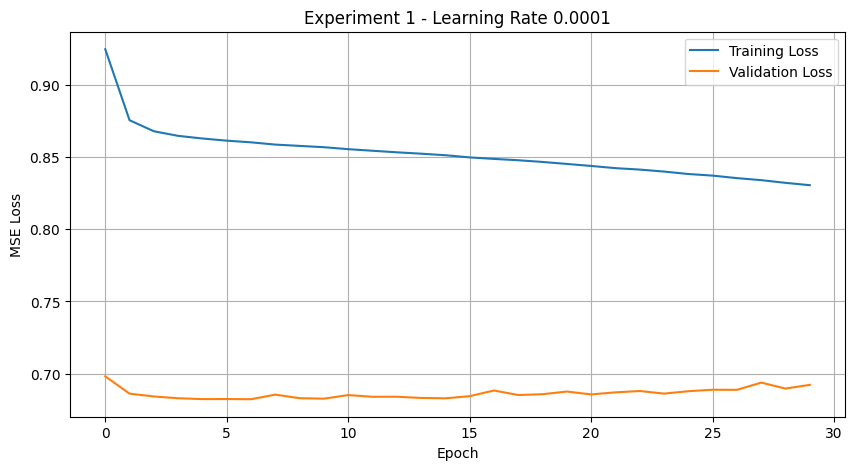

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(exp1_train_losses, label="Training Loss")
plt.plot(exp1_val_losses, label="Validation Loss")

plt.title("Experiment 1 - Learning Rate 0.0001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [39]:
# Create a fresh DNN model
exp2_model = DeepNeuralNetwork(input_size=315)

# Define optimizer
exp2_optimizer = optim.Adam(
    exp2_model.parameters(),
    lr=0.01
)

# Store losses
exp2_train_losses = []
exp2_val_losses = []

print("Experiment 2 setup completed!")

Experiment 2 setup completed!


In [40]:
for epoch in range(30):

    exp2_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp2_model(X_batch)

        loss = criterion(predictions, y_batch)

        exp2_optimizer.zero_grad()

        loss.backward()

        exp2_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp2_model.eval()

    with torch.no_grad():

        val_predictions = exp2_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 2 completed!")

Epoch [1/30], Train Loss: 0.8836, Val Loss: 0.6898
Epoch [2/30], Train Loss: 0.8730, Val Loss: 0.6890
Epoch [3/30], Train Loss: 0.8670, Val Loss: 0.6932
Epoch [4/30], Train Loss: 0.8651, Val Loss: 0.6849
Epoch [5/30], Train Loss: 0.8633, Val Loss: 0.7051
Epoch [6/30], Train Loss: 0.8581, Val Loss: 0.6908
Epoch [7/30], Train Loss: 0.8526, Val Loss: 0.6897
Epoch [8/30], Train Loss: 0.8484, Val Loss: 0.6972
Epoch [9/30], Train Loss: 0.8432, Val Loss: 0.6919
Epoch [10/30], Train Loss: 0.8380, Val Loss: 0.6918
Epoch [11/30], Train Loss: 0.8307, Val Loss: 0.6954
Epoch [12/30], Train Loss: 0.8243, Val Loss: 0.6909
Epoch [13/30], Train Loss: 0.8142, Val Loss: 0.6961
Epoch [14/30], Train Loss: 0.8091, Val Loss: 0.6878
Epoch [15/30], Train Loss: 0.8019, Val Loss: 0.7092
Epoch [16/30], Train Loss: 0.8006, Val Loss: 0.7163
Epoch [17/30], Train Loss: 0.7855, Val Loss: 0.7261
Epoch [18/30], Train Loss: 0.7982, Val Loss: 0.7162
Epoch [19/30], Train Loss: 0.7896, Val Loss: 0.7107
Epoch [20/30], Train 

In [41]:
exp2_model.eval()

with torch.no_grad():

    exp2_val_scaled = exp2_model(X_val_tensor).numpy()

    exp2_val_predictions = target_scaler.inverse_transform(
        exp2_val_scaled
    )

exp2_val_mse = mean_squared_error(
    y_val,
    exp2_val_predictions
)

print("Experiment 2 Validation MSE:", exp2_val_mse)

Experiment 2 Validation MSE: 4769354752.0


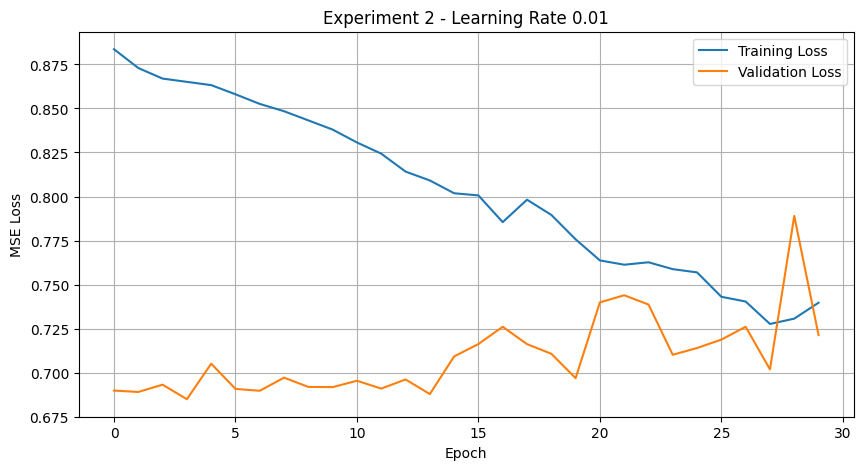

In [42]:
plt.figure(figsize=(10, 5))

plt.plot(exp2_train_losses, label="Training Loss")
plt.plot(exp2_val_losses, label="Validation Loss")

plt.title("Experiment 2 - Learning Rate 0.01")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [43]:
# Create a fresh DNN model
exp3_model = DeepNeuralNetwork(input_size=315)

# Define optimizer
exp3_optimizer = optim.Adam(
    exp3_model.parameters(),
    lr=0.1
)

# Store losses
exp3_train_losses = []
exp3_val_losses = []

print("Experiment 3 setup completed!")

Experiment 3 setup completed!


In [44]:
for epoch in range(30):

    exp3_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        predictions = exp3_model(X_batch)

        loss = criterion(predictions, y_batch)

        # Stop if loss becomes invalid
        if not torch.isfinite(loss):
            print("Training diverged!")
            break

        exp3_optimizer.zero_grad()

        loss.backward()

        exp3_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    if not torch.isfinite(loss):
        break

    train_loss = total_train_loss / len(train_dataset)

    exp3_model.eval()

    with torch.no_grad():

        val_predictions = exp3_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    if not np.isfinite(val_loss):
        print("Validation loss became invalid!")
        break

    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 3 completed!")

Epoch [1/30], Train Loss: 1.1886, Val Loss: 0.6942
Epoch [2/30], Train Loss: 0.8844, Val Loss: 0.6894
Epoch [3/30], Train Loss: 0.8849, Val Loss: 0.6916
Epoch [4/30], Train Loss: 0.8898, Val Loss: 0.6976
Epoch [5/30], Train Loss: 0.9505, Val Loss: 0.8185
Epoch [6/30], Train Loss: 1.0010, Val Loss: 0.8168
Epoch [7/30], Train Loss: 1.0021, Val Loss: 0.8169
Epoch [8/30], Train Loss: 1.0014, Val Loss: 0.8206
Epoch [9/30], Train Loss: 1.0016, Val Loss: 0.8165
Epoch [10/30], Train Loss: 1.0026, Val Loss: 0.8165
Epoch [11/30], Train Loss: 1.0029, Val Loss: 0.8182
Epoch [12/30], Train Loss: 1.0022, Val Loss: 0.8170
Epoch [13/30], Train Loss: 1.0101, Val Loss: 0.8173
Epoch [14/30], Train Loss: 1.0021, Val Loss: 0.8183
Epoch [15/30], Train Loss: 1.0018, Val Loss: 0.8219
Epoch [16/30], Train Loss: 1.0021, Val Loss: 0.8204
Epoch [17/30], Train Loss: 1.0031, Val Loss: 0.8178
Epoch [18/30], Train Loss: 1.0023, Val Loss: 0.8185
Epoch [19/30], Train Loss: 1.0035, Val Loss: 0.8167
Epoch [20/30], Train 

In [45]:
exp3_model.eval()

with torch.no_grad():

    exp3_val_scaled = exp3_model(X_val_tensor).numpy()

    exp3_val_predictions = target_scaler.inverse_transform(
        exp3_val_scaled
    )

exp3_val_mse = mean_squared_error(
    y_val,
    exp3_val_predictions
)

print("Experiment 3 Validation MSE:", exp3_val_mse)

Experiment 3 Validation MSE: 5401866240.0


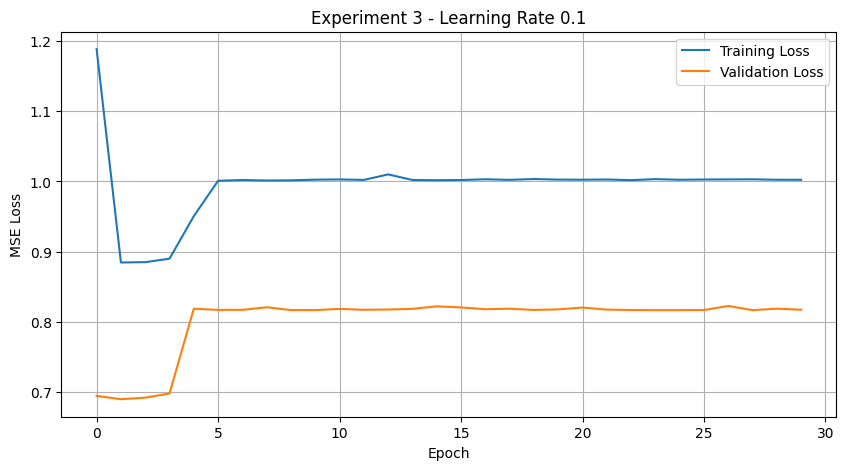

In [46]:
plt.figure(figsize=(10, 5))

plt.plot(exp3_train_losses, label="Training Loss")
plt.plot(exp3_val_losses, label="Validation Loss")

plt.title("Experiment 3 - Learning Rate 0.1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()